# 14 · Statistics for Data Science: Hands-on Tutorial

Charts show patterns. Statistics tells you **how much to trust them**.

We'll use the shop data from topics 12–13 to answer questions like:
- What is a "typical" order, and how much do orders vary?
- If we only had a sample, how sure could we be about the average?
- Clothing orders *look* bigger. Is that **real**, or could it be **chance**?
- Thursday has 54 orders and Sunday only 31. Does the weekday matter?

Read the concepts in [README.md](README.md). All outputs are saved, so you can read this on GitHub.

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

sys.path.insert(0, "../13_visualisation")
import chart_style as cs   # the same chart style as topic 13

cs.apply()
rng = np.random.default_rng(seed=14)   # fixed seed: the same "random" results every run

sales = pd.read_csv("../12_pandas/data/sales_clean.csv", parse_dates=["order_date"])
revenue = sales["revenue"]
print(len(sales), "orders")

297 orders


# Part A: Describing data

## 1. Centre: mean, median, mode

| Measure | Meaning | Good for |
|---------|---------|----------|
| **Mean** | Sum ÷ count | Symmetric data without extreme values |
| **Median** | The middle value when sorted | Skewed data, data with outliers (incomes, prices, order values) |
| **Mode** | The most common value | Categories, or "what do people usually buy?" |

In [2]:
pd.Series({
    "mean": revenue.mean(),
    "median": revenue.median(),
    "mode": revenue.mode()[0],
}).round(0)

mean      2308.0
median    1497.0
mode       499.0
dtype: float64

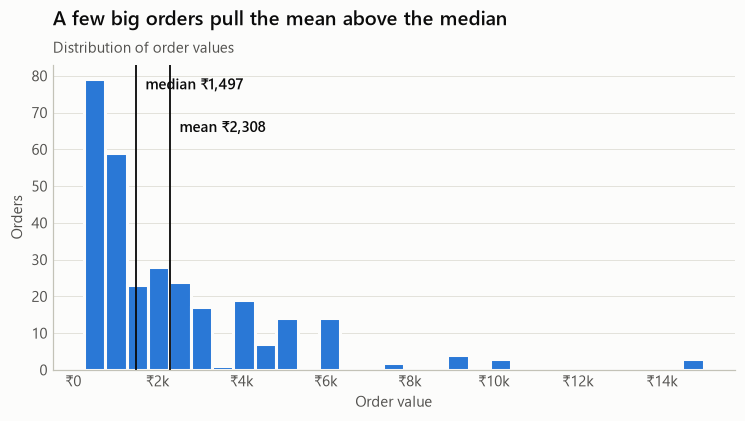

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.histplot(revenue, binwidth=500, color=cs.PRIMARY, edgecolor=cs.SURFACE, linewidth=2, alpha=1, ax=ax)
top = ax.get_ylim()[1]
for value, name, height in [(revenue.median(), "median", 0.92), (revenue.mean(), "mean", 0.78)]:
    ax.axvline(value, color=cs.INK, linewidth=1.2)
    ax.annotate(f"{name} ₹{value:,.0f}", (value, top * height), xytext=(6, 0), textcoords="offset points",
                fontweight="semibold")
ax.xaxis.set_major_formatter(cs.RUPEES)
ax.set(xlabel="Order value", ylabel="Orders")
cs.only_grid(ax, "y")
cs.title(ax, "A few big orders pull the mean above the median", "Distribution of order values")
plt.show()

The mean (₹2,308) is **54% higher** than the median (₹1,497). Half of all orders are below ₹1,497, so if someone asked "what does a typical customer spend?", the **median** is the honest answer.

## 2. Spread: how much do values vary?

In [4]:
q1, q3 = revenue.quantile([0.25, 0.75])
pd.Series({
    "min": revenue.min(),
    "max": revenue.max(),
    "range": revenue.max() - revenue.min(),
    "std (standard deviation)": revenue.std(),
    "Q1 (25th percentile)": q1,
    "Q3 (75th percentile)": q3,
    "IQR (Q3 - Q1)": q3 - q1,
    "90th percentile": revenue.quantile(0.9),
    "skewness": revenue.skew(),
}).round(2)

min                           249.00
max                         14997.00
range                       14748.00
std (standard deviation)     2377.27
Q1 (25th percentile)          698.00
Q3 (75th percentile)         2999.00
IQR (Q3 - Q1)                2301.00
90th percentile              4999.00
skewness                        2.40
dtype: float64

- **Standard deviation** is roughly "how far a typical value is from the mean". Like the mean, it is pulled up by extreme values.
- **IQR** is the range of the middle 50%. It ignores the extremes, so it pairs naturally with the median.
- **Skewness** of 2.4 confirms a strong **right skew** (a long tail of large values). 0 would be symmetric.

## 3. Outliers: two common rules

In [5]:
upper_fence = q3 + 1.5 * (q3 - q1)
z_scores = (revenue - revenue.mean()) / revenue.std()

print(f"IQR rule  (above ₹{upper_fence:,.0f}): {(revenue > upper_fence).sum()} outliers")
print(f"z-score rule (|z| > 3):         {(z_scores.abs() > 3).sum()} outliers")

IQR rule  (above ₹6,450): 12 outliers
z-score rule (|z| > 3):         6 outliers


The two rules disagree. The **z-score** rule assumes the data is roughly bell-shaped (normal), and ours is strongly skewed, so the **IQR rule** is more trustworthy here. (It's the rule box plots use.)

**An outlier is not automatically an error.** A ₹15,000 order is unusual but real, and it's a valuable customer. Investigate outliers before you remove anything.

# Part B: Distributions and sampling

## 4. The normal distribution

Many natural measurements (heights, measurement errors, exam scores) follow the bell-shaped **normal distribution**. It is described by just two numbers: the mean (μ) and the standard deviation (σ).

The **68–95–99.7 rule**: about 68% of values lie within 1σ of the mean, 95% within 2σ, and 99.7% within 3σ.

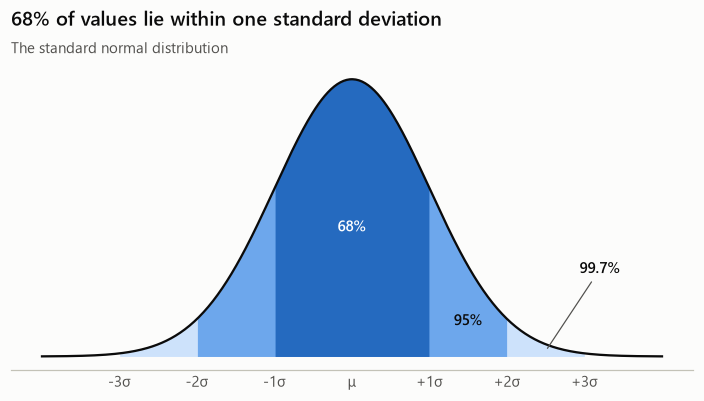

In [6]:
x = np.linspace(-4, 4, 400)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(x, stats.norm.pdf(x), color=cs.INK, linewidth=1.5)
for k, shade in [(3, cs.BLUE_RAMP[0]), (2, cs.BLUE_RAMP[2]), (1, cs.BLUE_RAMP[4])]:
    band = (x >= -k) & (x <= k)
    ax.fill_between(x[band], stats.norm.pdf(x[band]), color=shade, linewidth=0)
ax.annotate("68%", (0, 0.18), ha="center", fontweight="semibold", color="#ffffff")
ax.annotate("95%", (1.5, 0.045), ha="center", fontweight="semibold", color=cs.INK)
ax.annotate("99.7%", xy=(2.5, 0.008), xytext=(3.2, 0.12), ha="center", fontweight="semibold",
            arrowprops={"arrowstyle": "-", "color": cs.INK_SECONDARY, "linewidth": 0.8})
ax.set_xticks(range(-3, 4), [f"{k:+d}σ" if k else "μ" for k in range(-3, 4)])
ax.set_yticks([])
ax.grid(False)
ax.spines["left"].set_visible(False)
cs.title(ax, "68% of values lie within one standard deviation", "The standard normal distribution")
plt.show()

In [7]:
# Check the rule with 100,000 simulated exam scores (mean 60, std 10)
scores = rng.normal(loc=60, scale=10, size=100_000)
for k in (1, 2, 3):
    share = (np.abs(scores - 60) <= k * 10).mean()
    print(f"within {k} std: {share:.1%}")

within 1 std: 68.2%
within 2 std: 95.5%
within 3 std: 99.8%


A **z-score** says how many standard deviations a value is from the mean: `z = (x - mean) / std`. A score of 80 here has z = +2, which puts it in the top ~2.5%.

## 5. Samples and the Central Limit Theorem

We rarely see a whole **population** (every customer, every order ever). We work with a **sample** and use it to estimate the population.

The **Central Limit Theorem (CLT)** is the reason this works: if you take many samples and compute each sample's mean, **those means form a bell curve, even when the original data is skewed**, as long as the samples are large enough (about 30+ is a common rule of thumb).

Let's prove it. We treat our 297 orders as the "population", take thousands of random samples, and plot their means:

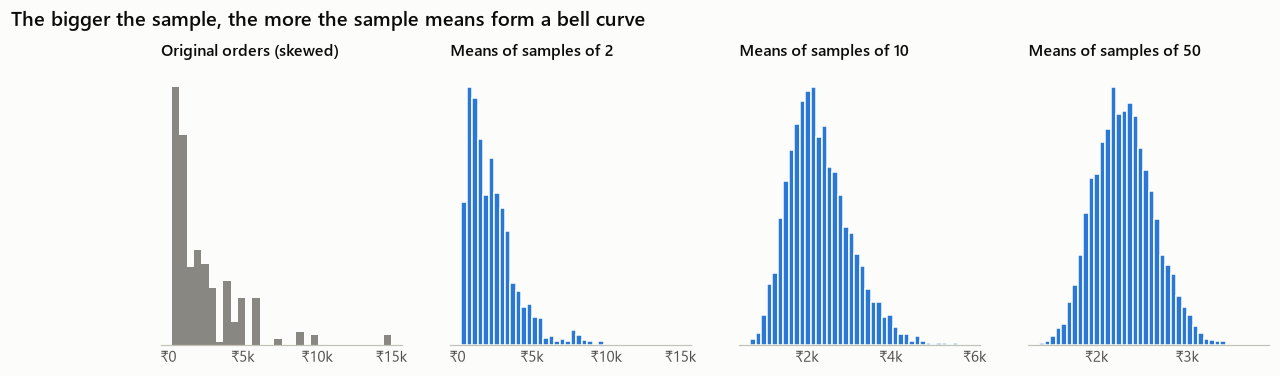

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
sns.histplot(revenue, bins=30, color=cs.MUTED, edgecolor=cs.SURFACE, alpha=1, ax=axes[0])
axes[0].set_title("Original orders (skewed)", fontsize=10.5)
for ax, n in zip(axes[1:], [2, 10, 50]):
    means = rng.choice(revenue, size=(5000, n)).mean(axis=1)
    sns.histplot(means, bins=40, color=cs.PRIMARY, edgecolor=cs.SURFACE, linewidth=1, alpha=1, ax=ax)
    ax.set_title(f"Means of samples of {n}", fontsize=10.5)
for ax in axes:
    ax.set(xlabel="", ylabel="", yticks=[])
    ax.xaxis.set_major_formatter(cs.RUPEES)
    ax.grid(False)
    ax.spines["left"].set_visible(False)
fig.suptitle("The bigger the sample, the more the sample means form a bell curve",
             x=0.02, ha="left", fontsize=13, fontweight="semibold", y=1.06)
plt.show()

As the sample size grows, the means become **bell-shaped** and **narrower**. Bigger samples give more precise estimates. The spread of these sample means is called the **standard error**: `std / √n`.

# Part C: Estimating with confidence

## 6. Confidence intervals

A single number like "the average order is ₹2,308" hides the uncertainty. A **95% confidence interval** gives a range instead.

In [9]:
mean = revenue.mean()
sem = stats.sem(revenue)            # standard error of the mean = std / sqrt(n)
low, high = stats.t.interval(0.95, df=len(revenue) - 1, loc=mean, scale=sem)
print(f"Mean order value: ₹{mean:,.0f}")
print(f"95% confidence interval (t): ₹{low:,.0f} to ₹{high:,.0f}")

Mean order value: ₹2,308
95% confidence interval (t): ₹2,037 to ₹2,580


**Bootstrap**: a modern alternative that needs no formula. Resample the data *with replacement* thousands of times, compute the mean each time, and take the middle 95%. It works for medians and almost any other statistic too.

In [10]:
boot_means = np.array([rng.choice(revenue, size=len(revenue)).mean() for _ in range(10_000)])
boot_medians = np.array([np.median(rng.choice(revenue, size=len(revenue))) for _ in range(10_000)])
print("95% bootstrap CI for the mean:   ₹{:,.0f} to ₹{:,.0f}".format(*np.percentile(boot_means, [2.5, 97.5])))
print("95% bootstrap CI for the median: ₹{:,.0f} to ₹{:,.0f}".format(*np.percentile(boot_medians, [2.5, 97.5])))

95% bootstrap CI for the mean:   ₹2,046 to ₹2,581
95% bootstrap CI for the median: ₹1,199 to ₹1,798


**What "95% confident" really means:** if we repeated the sampling many times, **95% of the intervals we built would contain the true value**. It's a statement about the *method*, not a 95% chance for one particular interval.

Let's see it. Treat the 297 orders as the population (so we know the true mean), draw 25 samples of 40 orders, and build a 95% interval from each:

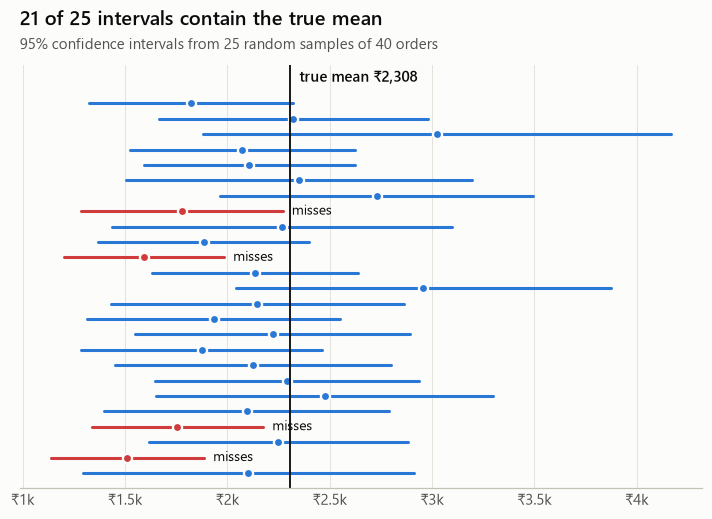

In [11]:
true_mean = revenue.mean()
fig, ax = plt.subplots(figsize=(8, 5))
misses = 0
for i in range(25):
    sample = rng.choice(revenue, size=40, replace=False)
    lo, hi = stats.t.interval(0.95, df=39, loc=sample.mean(), scale=stats.sem(sample))
    hit = lo <= true_mean <= hi
    misses += not hit
    color = cs.PRIMARY if hit else "#d03b3b"
    ax.plot([lo, hi], [i, i], color=color, linewidth=2, solid_capstyle="round")
    ax.plot(sample.mean(), i, "o", color=color, markeredgecolor=cs.SURFACE, markeredgewidth=1.5)
    if not hit:
        ax.annotate("misses", (hi, i), xytext=(6, 0), textcoords="offset points", va="center",
                    color=cs.INK, fontsize=9)
ax.axvline(true_mean, color=cs.INK, linewidth=1.2)
ax.set_ylim(-1, 26.5)
ax.annotate(f"true mean ₹{true_mean:,.0f}", (true_mean, 25.4), xytext=(6, 0), textcoords="offset points",
            fontweight="semibold")
ax.set_yticks([])
ax.xaxis.set_major_formatter(cs.RUPEES)
cs.only_grid(ax, "x")
ax.spines["left"].set_visible(False)
cs.title(ax, f"{25 - misses} of 25 intervals contain the true mean", "95% confidence intervals from 25 random samples of 40 orders")
plt.show()

We expected about 1 miss in 25 (5%) and got 4. Part of that is luck with only 25 intervals. Part of it is our data: with **skewed data and small samples**, the t-interval comes out a little too narrow. The formula assumes the sample means are bell-shaped, and with n = 40 from such a skewed population they aren't quite there yet (look back at the CLT chart). That's one reason the **bootstrap** is popular, and a reminder that every statistical method has **assumptions**.

# Part D: Hypothesis testing: is a difference real?

## 7. The idea

Clothing orders average ₹3,846, while all other orders average ₹1,927. But differences appear by chance all the time. A hypothesis test asks:

> **If there were really no difference, how surprising would our data be?**

| Term | Meaning |
|------|---------|
| **Null hypothesis (H₀)** | "Nothing is going on": no difference, no effect |
| **Alternative (H₁)** | "There is a difference" |
| **p-value** | The probability of a result **at least this extreme if H₀ were true** |
| **α (alpha)** | The cut-off you choose in advance, usually 0.05 |
| **Decision** | p < α → reject H₀ ("statistically significant"); p ≥ α → not enough evidence |

## 8. A permutation test: see the p-value with your own eyes

If category truly didn't matter, the "Clothing" labels could be shuffled randomly among the orders without changing anything. So let's **shuffle them 10,000 times** and see how often chance alone produces a difference as big as the real one.

In [12]:
is_clothing = (sales["category"] == "Clothing").to_numpy()
values = revenue.to_numpy()
observed = values[is_clothing].mean() - values[~is_clothing].mean()

shuffled_diffs = np.empty(10_000)
for i in range(10_000):
    labels = rng.permutation(is_clothing)
    shuffled_diffs[i] = values[labels].mean() - values[~labels].mean()
p_perm = (np.abs(shuffled_diffs) >= abs(observed)).mean()

print(f"Observed difference: ₹{observed:,.0f}")
print(f"Shuffles at least that extreme: {(np.abs(shuffled_diffs) >= abs(observed)).sum()} of 10,000  ->  p ≈ {p_perm:.4f}")

Observed difference: ₹1,919
Shuffles at least that extreme: 0 of 10,000  ->  p ≈ 0.0000


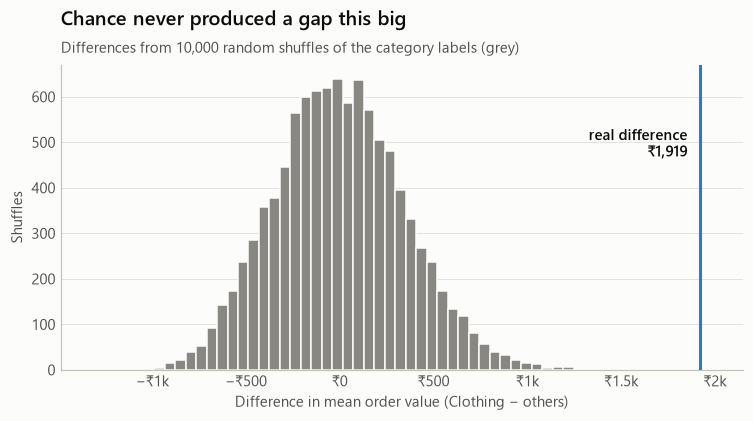

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.histplot(shuffled_diffs, bins=50, color=cs.MUTED, edgecolor=cs.SURFACE, linewidth=1, alpha=1, ax=ax)
ax.axvline(observed, color=cs.PRIMARY, linewidth=2)
ax.set_xlim(right=observed * 1.12)
ax.annotate(f"real difference\n₹{observed:,.0f}", (observed, ax.get_ylim()[1] * 0.7), xytext=(-8, 0),
            textcoords="offset points", ha="right", color=cs.INK, fontweight="semibold")
ax.xaxis.set_major_formatter(cs.RUPEES)
ax.set(xlabel="Difference in mean order value (Clothing − others)", ylabel="Shuffles")
cs.only_grid(ax, "y")
cs.title(ax, "Chance never produced a gap this big", "Differences from 10,000 random shuffles of the category labels (grey)")
plt.show()

In 10,000 shuffles, chance **never** came close to the real gap. So the p-value is below 0.0001, and the difference is real.

The standard tests reach the same conclusion in one line each:

In [14]:
clothing = revenue[sales["category"] == "Clothing"]
others = revenue[sales["category"] != "Clothing"]

t = stats.ttest_ind(clothing, others, equal_var=False)      # Welch's t-test: compares means
u = stats.mannwhitneyu(clothing, others)                     # Mann-Whitney U: compares ranks (no normality needed)
print(f"Welch t-test:   t = {t.statistic:.2f}, p = {t.pvalue:.2g}")
print(f"Mann-Whitney U: p = {u.pvalue:.2g}")

# Effect size: HOW BIG is the difference, in standard deviations? (Cohen's d)
pooled_sd = np.sqrt((clothing.var() + others.var()) / 2)
print(f"Cohen's d = {(clothing.mean() - others.mean()) / pooled_sd:.2f}   (0.2 small, 0.5 medium, 0.8 large)")

Welch t-test:   t = 6.33, p = 7.4e-09
Mann-Whitney U: p = 2.8e-15
Cohen's d = 0.88   (0.2 small, 0.5 medium, 0.8 large)


## 9. Choosing the right test matters: Clothing vs Electronics

Now compare Clothing with Electronics only:

In [15]:
electronics = revenue[sales["category"] == "Electronics"]
print(f"Clothing:    mean ₹{clothing.mean():,.0f}, median ₹{clothing.median():,.0f}")
print(f"Electronics: mean ₹{electronics.mean():,.0f}, median ₹{electronics.median():,.0f}")
print()
print(f"Welch t-test   p = {stats.ttest_ind(clothing, electronics, equal_var=False).pvalue:.3f}")
print(f"Mann-Whitney U p = {stats.mannwhitneyu(clothing, electronics).pvalue:.4f}")

Clothing:    mean ₹3,846, median ₹2,999
Electronics: mean ₹3,147, median ₹1,999

Welch t-test   p = 0.098
Mann-Whitney U p = 0.0006


**The two tests disagree!**
- The **t-test** compares *means*. Electronics has some very large orders (up to ₹15,000) that raise its mean and its variance, so the t-test can't separate the groups (p = 0.098).
- **Mann-Whitney** compares *typical values* (ranks), so it isn't thrown off by a few big orders. It finds that a typical Clothing order really is larger (p = 0.0006).

Our data is strongly skewed, so the rank-based test answers the business question better. **Check your data's shape before choosing a test**, and decide which test to use *before* seeing the results.

## 10. Chi-square goodness of fit: does the weekday matter?

In [16]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_counts = sales["order_date"].dt.day_name().value_counts().reindex(days)
print(weekday_counts.to_string())
result = stats.chisquare(weekday_counts)       # H0: orders are spread evenly over the 7 days
print(f"\nchi-square = {result.statistic:.2f}, p = {result.pvalue:.2f}")

order_date
Monday       41
Tuesday      49
Wednesday    37
Thursday     54
Friday       42
Saturday     43
Sunday       31

chi-square = 8.01, p = 0.24


Thursday (54) has **74% more** orders than Sunday (31). That looks like a pattern you might build a marketing plan on. But **p = 0.24**: with only ~300 orders, counts this uneven happen by chance about a quarter of the time when the days are truly equal.

**Not significant ≠ "no difference".** It means *this data can't tell*. Collect more data before acting on it.

## 11. Chi-square test of independence: city vs payment method

Do people in different cities prefer different payment methods?

In [17]:
table = pd.crosstab(sales["city"], sales["payment_method"])
display(table)
chi2, p, dof, expected = stats.chi2_contingency(table)
print(f"chi-square = {chi2:.1f}, degrees of freedom = {dof}, p = {p:.2f}")

payment_method,Card,Cash on Delivery,UPI,Unknown
city,,,,
Bengaluru,11,2,23,1
Delhi,14,13,39,1
Hyderabad,10,6,15,1
Mumbai,25,16,36,3
Pune,15,24,40,2


chi-square = 14.3, degrees of freedom = 12, p = 0.28


p = 0.28, so there's no evidence that payment habits differ by city. (Some cells have small counts, so treat this with caution. The test is most reliable when every *expected* count is 5 or more.)

## 12. Correlation: are two numbers related?

In [18]:
daily = sales.groupby("order_date").agg(orders=("order_id", "count"), revenue=("revenue", "sum"))
pearson = stats.pearsonr(daily["orders"], daily["revenue"])
spearman = stats.spearmanr(daily["orders"], daily["revenue"])
print(f"Pearson  r   = {pearson.statistic:.2f}, p = {pearson.pvalue:.1g}   (straight-line relationship)")
print(f"Spearman rho = {spearman.statistic:.2f}, p = {spearman.pvalue:.1g}   (any rising/falling relationship, robust to outliers)")

Pearson  r   = 0.64, p = 1e-17   (straight-line relationship)
Spearman rho = 0.65, p = 2e-18   (any rising/falling relationship, robust to outliers)


Busier days clearly earn more. But remember: **correlation is not causation**. Ice-cream sales and drowning deaths are correlated because both rise in summer, not because one causes the other. Only a controlled **experiment** proves cause and effect, which brings us to A/B tests.

## 13. A/B test: did the new checkout page work?

The shop tests a new checkout page. 2,400 visitors see the old page (A) and 2,400 see the new one (B). This is the most common hypothesis test in industry.

In [19]:
ab = pd.DataFrame({"bought": [120, 156], "visitors": [2400, 2400]}, index=["A (old)", "B (new)"])
ab["conversion"] = ab["bought"] / ab["visitors"]
display(ab.style.format({"conversion": "{:.1%}"}))

chi2, p, _, _ = stats.chi2_contingency([[120, 2400 - 120], [156, 2400 - 156]])
lift = ab.loc["B (new)", "conversion"] - ab.loc["A (old)", "conversion"]
print(f"Lift: +{lift:.1%} points ({lift / ab.loc['A (old)', 'conversion']:.0%} relative), p = {p:.3f}")

,bought,visitors,conversion
A (old),120,2400,5.0%
B (new),156,2400,6.5%


Lift: +1.5% points (30% relative), p = 0.030


p = 0.03 < 0.05, so the new page is **statistically significant** at the usual level.

Before shipping, still ask:
- **Is it practically significant?** +1.5 points is a 30% relative lift, which is meaningful for a shop.
- **Was the test planned?** Decide the sample size and α *before* starting, and don't stop early the moment p dips below 0.05 ("peeking" inflates false positives).
- **p = 0.03 is not "97% sure B is better".** It means that *if A and B were truly equal*, a gap this large would appear about 3% of the time.

## What you learned

| Question | Tool |
|----------|------|
| What's typical? | Median for skewed data, mean for symmetric data |
| How spread out? | IQR (skewed), standard deviation (symmetric) |
| Which values are unusual? | IQR rule (1.5 × IQR beyond Q1/Q3) |
| How precise is my estimate? | Confidence interval (t-interval or bootstrap) |
| Do two groups differ (numbers)? | Welch's t-test (means), Mann-Whitney U (skewed data) |
| Do counts match expectations? | Chi-square goodness of fit |
| Are two categories related? | Chi-square test of independence |
| Are two numbers related? | Pearson / Spearman correlation |
| Did a change work? | A/B test (two-proportion / chi-square) |

**Next:** topic 15 puts everything together in a full exploratory data analysis (EDA) project.